# ECG R-peak detection on the MIT-BIH Arrhythmia Database

**Goal:** detect heartbeats (R-peaks) in a single-lead ECG and measure how well the detector agrees with expert annotations.

**Specification**

| Parameter | Target |
|---|---|
| Sensitivity (real beats found / real beats) | above 99 % |
| Precision (real beats / beats reported) | above 99 % |
| Matching tolerance | 150 ms around each expert label |

**Data:** MIT-BIH Arrhythmia Database (PhysioNet), lead MLII, 360 Hz, first 5 minutes of each record. The data were recorded in the USA, so mains interference is at **60 Hz** (it would be 50 Hz in Europe).

**Pipeline:** load, inspect the spectrum, band-pass 0.5 to 40 Hz and notch the mains, detect beats, compare with expert labels, analyse failures.

**How to run:** Runtime, then Run all (about 3 minutes).

In [1]:
!pip install wfdb -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt, find_peaks, welch

DB = 'mitdb'                          # MIT-BIH Arrhythmia Database (PhysioNet)
BEAT_SYMBOLS = 'NLRBAaJSVrFejnE/fQ'   # annotation symbols that mark a beat
TOL_S = 0.15                          # matching tolerance (s)
SECONDS = 300                         # analyse the first 5 minutes of each record
MAINS = 60                            # Hz, mains frequency in the USA

## Helper functions

- `clean`: 4th-order Butterworth band-pass (0.5 to 40 Hz, zero-phase) plus a mains notch.
- `fixed_threshold_detector`: baseline detector, upward peaks above a fixed 0.5 mV prominence.
- `adaptive_detector`: simplified Pan-Tompkins method. It looks at fast slopes (5 to 15 Hz) instead of amplitude, so slow T-waves are ignored and downward beats are found. The threshold follows the local signal level.
- `evaluate`: matches detections to expert labels and returns true positives, false negatives and false positives.

In [2]:
def load_record(name, seconds=SECONDS):
    """Return (signal in mV, sampling rate, expert beat positions, lead name)."""
    n = int(seconds * 360)
    rec = wfdb.rdrecord(name, pn_dir=DB, sampto=n)
    ann = wfdb.rdann(name, 'atr', pn_dir=DB, sampto=n)
    ref = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym in BEAT_SYMBOLS])
    return rec.p_signal[:, 0], rec.fs, ref, rec.sig_name[0]


def clean(x, fs):
    """Band-pass 0.5-40 Hz (4th-order Butterworth, zero-phase) plus mains notch."""
    sos = butter(4, [0.5, 40], btype='bandpass', fs=fs, output='sos')
    y = sosfiltfilt(sos, x)
    b, a = iirnotch(MAINS, Q=30, fs=fs)
    return filtfilt(b, a, y)


def fixed_threshold_detector(x, fs):
    """Baseline: upward peaks with a fixed prominence of 0.5 mV."""
    y = clean(x, fs)
    peaks, _ = find_peaks(y, distance=int(0.25 * fs), prominence=0.5)
    return peaks


def adaptive_detector(x, fs):
    """QRS-energy detector with an adaptive threshold (simplified Pan-Tompkins)."""
    y = clean(x, fs)
    # 1. emphasise fast QRS slopes (5-15 Hz), suppress slow T-waves
    sos_q = butter(2, [5, 15], btype='bandpass', fs=fs, output='sos')
    q = sosfiltfilt(sos_q, x)
    energy = np.gradient(q) ** 2
    w = int(0.15 * fs)
    m = np.convolve(energy, np.ones(w) / w, mode='same')
    # 2. adaptive threshold: 30 % of the local 95th percentile (4 s window)
    level = pd.Series(m).rolling(int(4 * fs), center=True, min_periods=1).quantile(0.95).values
    cand, _ = find_peaks(m, distance=int(0.25 * fs))
    cand = cand[m[cand] > 0.3 * level[cand]]
    # 3. place each beat at the largest deflection (up or down) nearby
    half = int(0.1 * fs)
    peaks = []
    for c in cand:
        lo, hi = max(0, c - half), min(len(y), c + half)
        peaks.append(lo + np.argmax(np.abs(y[lo:hi])))
    return np.unique(peaks)


def evaluate(peaks, ref, fs):
    """Match detections to expert labels. Returns (TP, FN, FP)."""
    tol = int(TOL_S * fs)
    tp, matched = 0, set()
    for r in ref:
        idx = np.where(np.abs(peaks - r) <= tol)[0]
        if len(idx) > 0:
            tp += 1
            matched.add(idx[0])
    return tp, len(ref) - tp, len(peaks) - len(matched)


def sens_prec(tp, fn, fp):
    sens = 100 * tp / (tp + fn) if (tp + fn) > 0 else 0
    prec = 100 * tp / (tp + fp) if (tp + fp) > 0 else 0
    return sens, prec

## 1. Raw signal

Record 100, first 10 seconds. The baseline wanders slowly and the line is slightly noisy.

Sampling rate: 360 Hz | lead: MLII | samples: 36000


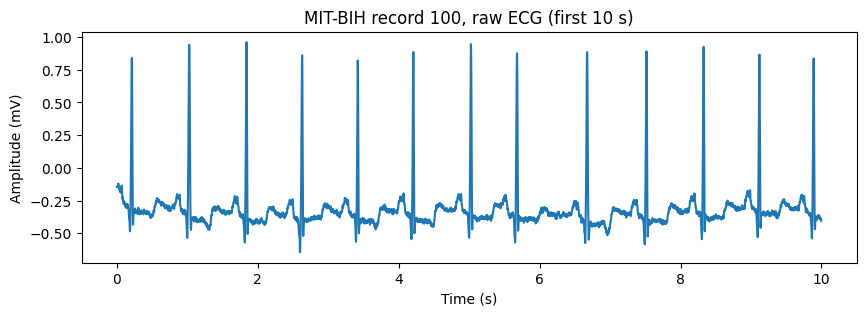

In [3]:
x, fs, ref, lead = load_record('100', seconds=100)
t = np.arange(len(x)) / fs
n10 = int(10 * fs)
print("Sampling rate:", fs, "Hz | lead:", lead, "| samples:", len(x))

plt.figure(figsize=(10, 3))
plt.plot(t[:n10], x[:n10])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.title("MIT-BIH record 100, raw ECG (first 10 s)")
plt.show()

## 2. Spectrum of the raw signal

Dashed lines mark 0.5, 40, 50 and 60 Hz. Expect strong low-frequency power (heart rate, harmonics and baseline drift), the main ECG band up to about 40 Hz, and a sharp mains spike. The spike is at **60 Hz**, not 50 Hz.

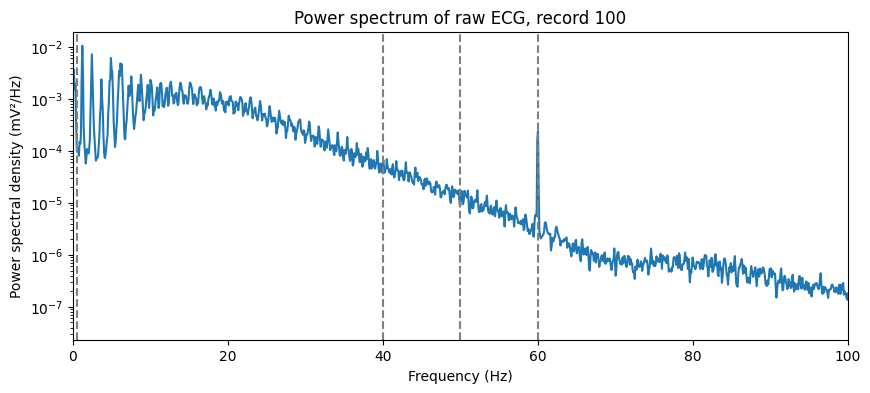

In [4]:
f, P_raw = welch(x, fs=fs, nperseg=4096)

plt.figure(figsize=(10, 4))
plt.semilogy(f, P_raw)
for fc in (0.5, 40, 50, 60):
    plt.axvline(fc, linestyle='--', color='gray')
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power spectral density (mV²/Hz)")
plt.title("Power spectrum of raw ECG, record 100")
plt.show()

## 3. Filtering

Digital counterpart of the analog band-pass built in LTspice (see the `ecg-filter-ltspice` repository). Zero-phase filtering runs the filter forward and backward, so it adds no delay but works offline only, and the effective -3 dB points move slightly inward because the response is applied twice.

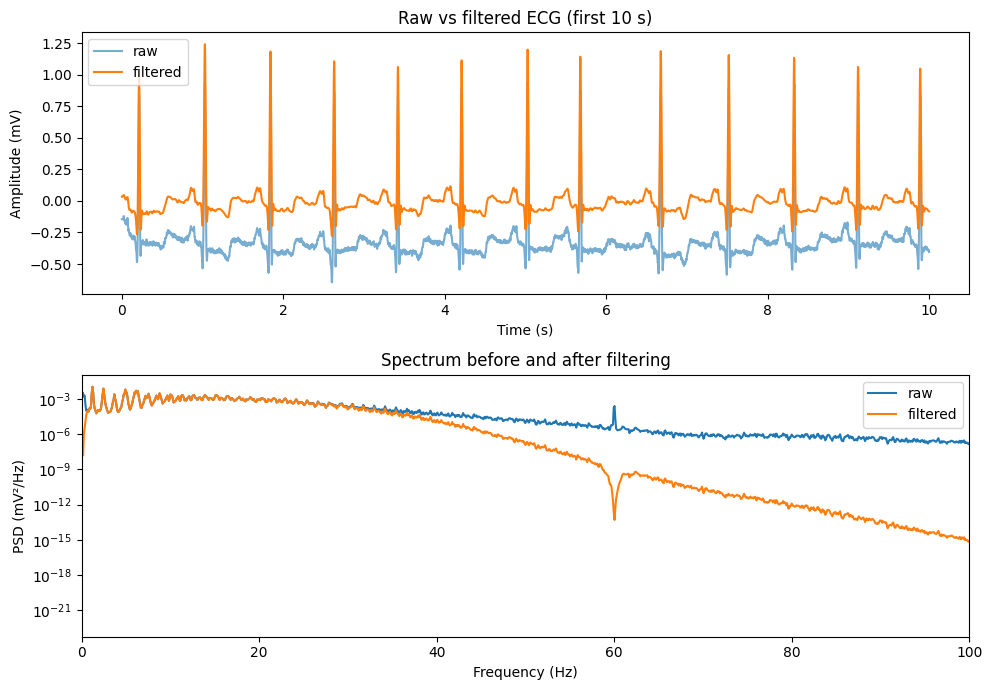

In [5]:
y = clean(x, fs)
f, P_flt = welch(y, fs=fs, nperseg=4096)

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
ax[0].plot(t[:n10], x[:n10], alpha=0.6, label="raw")
ax[0].plot(t[:n10], y[:n10], label="filtered")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude (mV)")
ax[0].set_title("Raw vs filtered ECG (first 10 s)")
ax[0].legend()

ax[1].semilogy(f, P_raw, label="raw")
ax[1].semilogy(f, P_flt, label="filtered")
ax[1].set_xlim(0, 100)
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("PSD (mV²/Hz)")
ax[1].set_title("Spectrum before and after filtering")
ax[1].legend()

plt.tight_layout()
plt.show()

## 4. Beat detection on a clean record

Record 100 with the adaptive detector. Red triangles are detected beats.

Detected beats: 371 | reference beats: 371 | TP 371 FN 0 FP 0
Mean heart rate: 74.2 bpm | sensitivity 100.00 % | precision 100.00 %


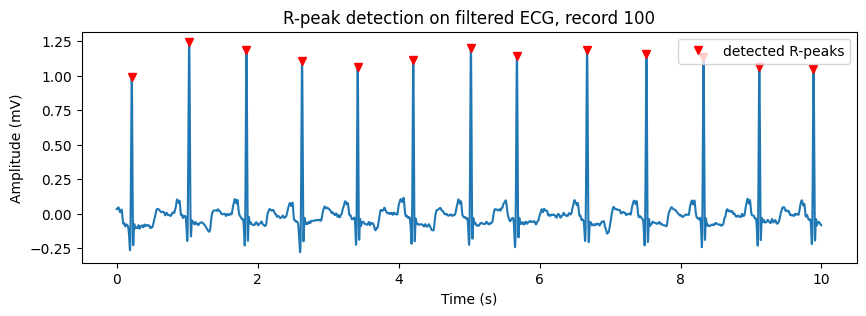

In [6]:
x, fs, ref, lead = load_record('100')
y = clean(x, fs)
t = np.arange(len(x)) / fs
peaks = adaptive_detector(x, fs)

tp, fn, fp = evaluate(peaks, ref, fs)
s, p = sens_prec(tp, fn, fp)
rr = np.diff(peaks) / fs
print("Detected beats: %d | reference beats: %d | TP %d FN %d FP %d" % (len(peaks), len(ref), tp, fn, fp))
print("Mean heart rate: %.1f bpm | sensitivity %.2f %% | precision %.2f %%" % (60 / rr.mean(), s, p))

n10 = int(10 * fs)
pk = peaks[peaks < n10]
plt.figure(figsize=(10, 3))
plt.plot(t[:n10], y[:n10])
plt.plot(pk / fs, y[pk], 'rv', label="detected R-peaks")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.title("R-peak detection on filtered ECG, record 100")
plt.legend()
plt.show()

## 5. Development set: fixed threshold vs adaptive detector

Ten records, including noisy and difficult ones. The fixed-threshold detector fails when T-waves are tall or when beats point downward. The adaptive detector was designed after inspecting these failures, so this set is the **development set**.

In [7]:
DEV = ['100', '101', '103', '105', '108', '119', '200', '203', '207', '219']
detectors = {"fixed": fixed_threshold_detector, "adaptive": adaptive_detector}

rows = []
tot = {k: [0, 0, 0] for k in detectors}
for name in DEV:
    x, fs, ref, lead = load_record(name)
    row = {"record": name, "beats": len(ref)}
    for label, det in detectors.items():
        tp, fn, fp = evaluate(det(x, fs), ref, fs)
        s, p = sens_prec(tp, fn, fp)
        row["sens_" + label], row["prec_" + label] = round(s, 1), round(p, 1)
        for i, v in enumerate((tp, fn, fp)):
            tot[label][i] += v
    rows.append(row)

print(pd.DataFrame(rows).to_string(index=False))
print()
for label in detectors:
    s, p = sens_prec(*tot[label])
    print("Overall %-8s detector: sensitivity %.2f %%, precision %.2f %%" % (label, s, p))

record  beats  sens_fixed  prec_fixed  sens_adaptive  prec_adaptive
   100    371       100.0       100.0          100.0          100.0
   101    342       100.0        98.6           99.7           99.4
   103    355       100.0        50.6          100.0          100.0
   105    417       100.0        99.5          100.0          100.0
   108    283        52.7        52.5          100.0          100.0
   119    326       100.0        67.2          100.0          100.0
   200    433        88.7        76.6           99.8          100.0
   203    499        92.6        89.7           90.0           99.8
   207    268        47.4        36.4           86.2           69.4
   219    381       100.0       100.0           99.7          100.0

Overall fixed    detector: sensitivity 90.18 %, precision 76.13 %
Overall adaptive detector: sensitivity 97.55 %, precision 97.15 %


## 6. Validation on unseen records

26 records that were **not** used for any design decision. The adaptive detector was not changed after this test.

In [8]:
UNSEEN = ['106', '115', '116', '121', '122', '123', '124', '201', '202',
          '205', '209', '210', '212', '213', '214', '215', '220', '221',
          '222', '223', '228', '230', '231', '232', '233', '234']

rows, tot_u = [], [0, 0, 0]
for name in UNSEEN:
    try:
        x, fs, ref, lead = load_record(name)
        tp, fn, fp = evaluate(adaptive_detector(x, fs), ref, fs)
    except Exception as e:
        print("Record", name, "failed:", e)
        continue
    s, p = sens_prec(tp, fn, fp)
    rows.append({"record": name, "lead": lead, "beats": len(ref),
                 "sens_%": round(s, 1), "prec_%": round(p, 1)})
    for i, v in enumerate((tp, fn, fp)):
        tot_u[i] += v

print(pd.DataFrame(rows).to_string(index=False))
s, p = sens_prec(*tot_u)
print("\nOverall (unseen records): sensitivity %.2f %%, precision %.2f %%" % (s, p))

record lead  beats  sens_%  prec_%
   106 MLII    331   100.0   100.0
   115 MLII    316   100.0   100.0
   116 MLII    395   100.0    99.7
   121 MLII    303   100.0   100.0
   122 MLII    422   100.0   100.0
   123 MLII    249   100.0   100.0
   124 MLII    252   100.0   100.0
   201 MLII    442   100.0   100.0
   202 MLII    265    98.5   100.0
   205 MLII    455   100.0   100.0
   209 MLII    486   100.0   100.0
   210 MLII    446    96.0    99.8
   212 MLII    463   100.0   100.0
   213 MLII    551    99.8   100.0
   214 MLII    383    98.7   100.0
   215 MLII    568    98.4   100.0
   220 MLII    354   100.0   100.0
   221 MLII    407    98.0   100.0
   222 MLII    367    96.5   100.0
   223 MLII    406    98.8   100.0
   228 MLII    350    86.0    99.3
   230 MLII    397   100.0   100.0
   231 MLII    293   100.0   100.0
   232 MLII    295   100.0   100.0
   233 MLII    518   100.0   100.0
   234 MLII    462   100.0   100.0

Overall (unseen records): sensitivity 98.90 %, precisi

## 7. Error analysis

The two weakest records, 228 (unseen) and 207 (development). Each plot is centred on the first missed beat: a green circle without a red triangle.

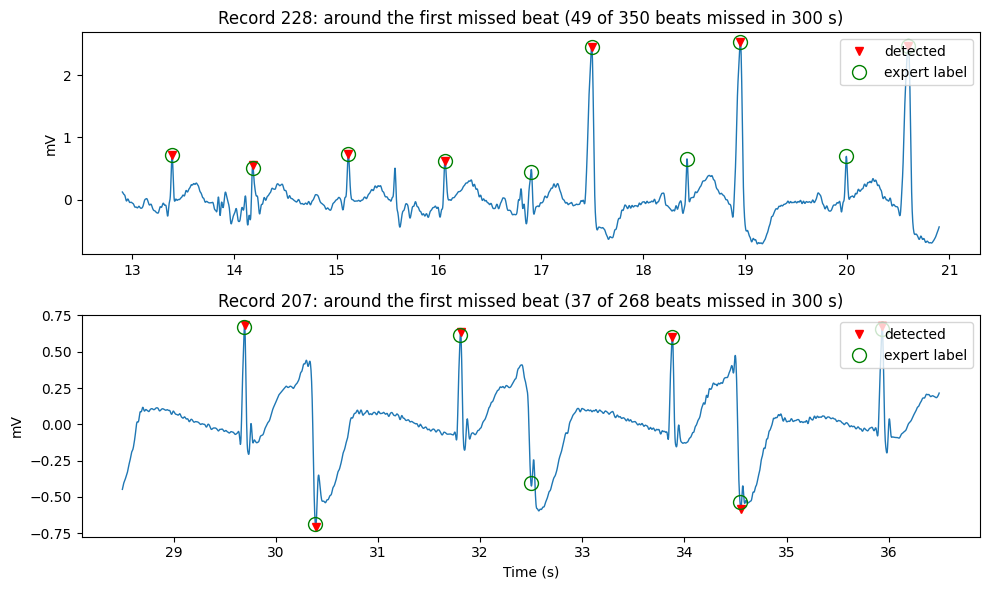

In [9]:
def show_misses(name, dur=8):
    x, fs, ref, lead = load_record(name)
    y = clean(x, fs)
    peaks = adaptive_detector(x, fs)
    tol = int(TOL_S * fs)
    missed = [r for r in ref if not np.any(np.abs(peaks - r) <= tol)]
    centre = missed[0] if missed else len(y) // 2
    i0 = int(max(0, centre - dur / 2 * fs))
    i1 = int(min(len(y), i0 + dur * fs))
    tt = np.arange(i0, i1) / fs

    plt.plot(tt, y[i0:i1], lw=1)
    p = peaks[(peaks >= i0) & (peaks < i1)]
    r = ref[(ref >= i0) & (ref < i1)]
    plt.plot(p / fs, y[p], 'rv', label='detected')
    plt.plot(r / fs, y[r], 'go', mfc='none', ms=10, label='expert label')
    plt.title("Record %s: around the first missed beat (%d of %d beats missed in %d s)"
              % (name, len(missed), len(ref), SECONDS))
    plt.ylabel('mV')
    plt.legend(loc='upper right')


plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
show_misses('228')
plt.subplot(2, 1, 2)
show_misses('207')
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()

## 8. Summary

| Set | Detector | Sensitivity | Precision |
|---|---|---|---|
| Development (10 records) | fixed threshold | 90.18 % | 76.13 % |
| Development (10 records) | adaptive | 97.55 % | 97.15 % |
| Unseen (26 records) | adaptive | 98.90 % | 99.96 % |

**Against the specification:** precision meets the 99 % target on the unseen set. Sensitivity (98.90 %) misses it by about 0.1 percentage points. The detector was deliberately **not** retuned on the unseen records, because that would remove the independence of the test.

**Failure modes seen in the inspected segments**

1. **Small beats between large ones (record 228).** The threshold follows the local 95th percentile of QRS energy. Energy grows roughly with the square of amplitude, so a beat much smaller than its tall neighbours falls below the threshold.
2. **Wide, slow abnormal beats (record 207).** Their slopes carry little energy in the 5 to 15 Hz band, so some are missed.

These come from a few inspected windows, not from a full classification of all misses.

**Limitations**

- 36 of the 48 records were tested, first 5 minutes only, lead MLII only. Not tested: 102, 104, 107, 217 (paced rhythms, usually excluded) and 109, 111, 112, 113, 114, 117, 118, 208.
- Beat detection only, no classification of beat type.
- Offline processing (zero-phase filters, whole-record windows). A real-time device would need causal filters and would add delay.
- The parameters (5 to 15 Hz band, ratio 0.3, 4 s window) were chosen by inspection of the development records, not by a systematic search.

**Next steps**

1. Tune the threshold ratio on a training subset with cross-validation and report the result on held-out records.
2. Normalise each beat's energy by its neighbours to handle mixed beat sizes.
3. Compare against an open-source reference detector (for example the XQRS detector in the `wfdb` package).
4. Build a causal, real-time version and measure its delay.